# TRICERATOPS validation of a NEMESIS candidate

This notebook uses `run_triceratops_on_nemesis` from the uploaded
`nemesis_triceratops.py` (version 1.3.0), retained **as-is** in
`examples/reference_wrappers/`. This wrapper is **not** an import from
the installed `nemesis_tess` package.

Requirements: an intact aperture `*_pix_mask.pkl`, a matching TESScut
FITS file, NEMESIS final LC, and a TLS bestfit. The preceding quickstart
must run with `keep_imagedata=True`, `keep_extra_files=True`,
`keep_FITS=True`, and `keep_extra_transit_files=True`. The wrapper may query TIC, MAST and TRILEGAL.

**Security:** the supplied wrapper temporarily disables Transport Layer Security verification
for the TRILEGAL hostname. Inspect that implementation before enabling
a remote validation run. It is disabled below by default.

**Scientific default:** 20 trials × 5,000,000 samples. The opt-in
single-trial smoke configuration is *not* a credible FPP measurement.


In [1]:
from pathlib import Path
import sys

# Find the example wrapper whether Jupyter was started at the repository
# root or within docs/notebooks/. Copy the provided wrapper alongside the
# notebook only if using these files without the repository clone.
candidates = [
    Path.cwd() / 'examples' / 'reference_wrappers',
    Path.cwd() / '..' / '..' / 'examples' / 'reference_wrappers',
]
roots = [p.resolve() for p in candidates if (p / 'nemesis_triceratops.py').exists()]
if not roots:
    raise FileNotFoundError(
        'Cannot locate examples/reference_wrappers/nemesis_triceratops.py. '
        'Open this notebook within a clone of the NEMESIS documentation repository.'
    )
sys.path.insert(0, str(roots[0]))
from nemesis_triceratops import run_triceratops_on_nemesis
print('Reference wrapper:', roots[0])


Reference wrapper: /Users/daxfeliz/Desktop/TESS/NEMESIS_II/NEMESIS_repo/examples/reference_wrappers


In [2]:
TIC_ID, SECTOR = 103633434, 20
OUTPUT = Path.home() / 'nemesis_tutorials' / 'toi1235_s20'
base = OUTPUT / f'Sector_{SECTOR:04d}'
lc_dir = base / 'NEMESIS_FFI_LCs'
tls_dir = base / 'NEMESIS_FFI_TLS_Report'
bestfit_path = tls_dir / f'TIC_{TIC_ID}_Sector_{SECTOR:04d}_TLS_bestfit.csv'
mask_path = lc_dir / f'TIC_{TIC_ID}_Sector_{SECTOR:04d}_pix_mask.pkl'

cutouts = sorted((OUTPUT / 'cache' / 'TESSCut').rglob('tess-s0020-*.fits'))
if not cutouts:
    cutouts = sorted(OUTPUT.rglob('tess-s0020-*.fits'))

required = [bestfit_path, mask_path]
missing = [str(p) for p in required if not p.exists()]
if not cutouts:
    missing.append('TESScut FITS cutout matching TIC/sector')
if missing:
    raise FileNotFoundError(
        'Required saved NEMESIS products are missing: ' + ', '.join(missing)
        + '. Rerun notebook 01 with keep_* flags enabled.'
    )
print('Bestfit:', bestfit_path)
print('Mask:', mask_path)
print('Candidate FITS cutouts:', cutouts)


Bestfit: /Users/daxfeliz/nemesis_tutorials/toi1235_s20/Sector_0020/NEMESIS_FFI_TLS_Report/TIC_103633434_Sector_0020_TLS_bestfit.csv
Mask: /Users/daxfeliz/nemesis_tutorials/toi1235_s20/Sector_0020/NEMESIS_FFI_LCs/TIC_103633434_Sector_0020_pix_mask.pkl
Candidate FITS cutouts: [PosixPath('/Users/daxfeliz/nemesis_tutorials/toi1235_s20/cache/TESSCut/tess-s0020-2-1_152.215862_69.276546_11x11_astrocut.fits')]


In [9]:
import numpy as np
import scipy.integrate as integrate

# ------------------------------------------------------------
# Compatibility: PyTransit 2.2.0 with NumPy 1.26 and SciPy 1.15
# ------------------------------------------------------------

# NumPy removed np.int in version 1.24.
if "int" not in np.__dict__:
    np.int = int

# SciPy removed scipy.integrate.trapz in version 1.14.
if not hasattr(integrate, "trapz"):
    integrate.trapz = integrate.trapezoid

# Verify that the actual TRICERATOPS modeling module imports.
from triceratops.triceratops import target

print("TRICERATOPS modeling import: PASS")

# ------------------------------------------------------------
# Scientific configuration
# ------------------------------------------------------------

USE_REFINED_EPHEMERIS = False
RUN_REMOTE_VALIDATION = True

posterior_path = None

if USE_REFINED_EPHEMERIS:
    import pandas as pd

    proposed = (
        OUTPUT / "jaxoplanet"
        / f"TIC_{TIC_ID}_Sector_{SECTOR:04d}_jaxoplanet_posterior.csv"
    )

    if not proposed.exists():
        raise FileNotFoundError(f"JAX posterior not found: {proposed}")

    rec = pd.read_csv(proposed).iloc[0]

    converged = str(
        rec.get("MCMC converged", "")
    ).lower() in ("true", "1")

    ceiling = float(
        rec.get("MCMC r ceiling frac", float("nan"))
    )

    if not converged or not (0 <= ceiling <= 0.01):
        raise ValueError(
            "Refit posterior failed convergence/prior-edge gates"
        )

    posterior_path = str(proposed)

# ------------------------------------------------------------
# TRICERATOPS validation
# ------------------------------------------------------------

if RUN_REMOTE_VALIDATION:
    result = run_triceratops_on_nemesis(
        tic_id=TIC_ID,
        sector=SECTOR,
        bestfit_path=str(bestfit_path),
        savelcpath=str(lc_dir),
        hdu=str(cutouts[0]),
        outdir=str(OUTPUT / "triceratops_tutorial"),
        n_trials=1,
        mc_samples=500_000,
        parallel=False,
        update_bestfit=True,
        append_to_vetting_report=True,
        posterior_path=posterior_path,
    )

    print(
        "Smoke-test result (NOT a reliable FPP):",
        result.get("FPP_median"),
    )
else:
    print("Remote TRICERATOPS computation skipped.")

TRICERATOPS modeling import: PASS
light curve   : /Users/daxfeliz/nemesis_tutorials/toi1235_s20/Sector_0020/NEMESIS_FFI_LCs/TIC_103633434_Sector_0020_final_LC.csv  (1183 rows)
window        : +/- 0.2078 d
points kept   : 100 of 982
mode          : unbinned  (median 1 per point)
in transit    : 18
out of transit: 72
flux_err      : 0.000226  (robust, on returned array)
median depth  : 0.000764  -> 14.3 sigma total
offset source : hdu[1] 1CRV4P/2CRV4P
corner        : col 537, row 93
pixels        : 16
CCD column    : 541 to 544
CCD row       : 96 to 100

TIC 103633434  Sector 20  (ephemeris: TLS, depth: TLS)
P_orb         : 3.4464013 d
T0            : 1845.514369 BTJD
duration      : 1.663 hr
tdepth        : 0.000770  (0.770 ppt)
aperture      : 16 pixels
LC points     : 100
conversion    : 1 - FCR = 0.999341 (Flux Contamination Ratio); dip handed 0.7690 ppt (survey 0.770 ppt); window +/- 3 durations
exptime       : 0.020813 d (29.97 min)
MC samples    : 500,000
TRILEGAL      : cached, /

/Users/daxfeliz/Desktop/TESS/NEMESIS_II/NEMESIS_repo/examples/reference_wrappers/nemesis_triceratops.py:3775: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  current[k] = v
/Users/daxfeliz/Desktop/TESS/NEMESIS_II/NEMESIS_repo/examples/reference_wrappers/nemesis_triceratops.py:3775: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  current[k] = v
/Users/daxfeliz/Desktop/TESS/NEMESIS_II/NEMESIS_repo/examples/reference_wrappers/nemesis_triceratops.py:3775: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of

**For a scientific validation run:** review the script's documentation,
use the full Monte Carlo settings, validate the NEMESIS-to-CCD pixel
conversion, inspect FCR handling and TRILEGAL caching, and evaluate
trial-to-trial FPP/NFPP distributions and stellar-host checks. You may
supply `posterior_path` **only** after the corresponding jaxoplanet
posterior passed quality gates; the wrapper verifies TIC/sector identity.


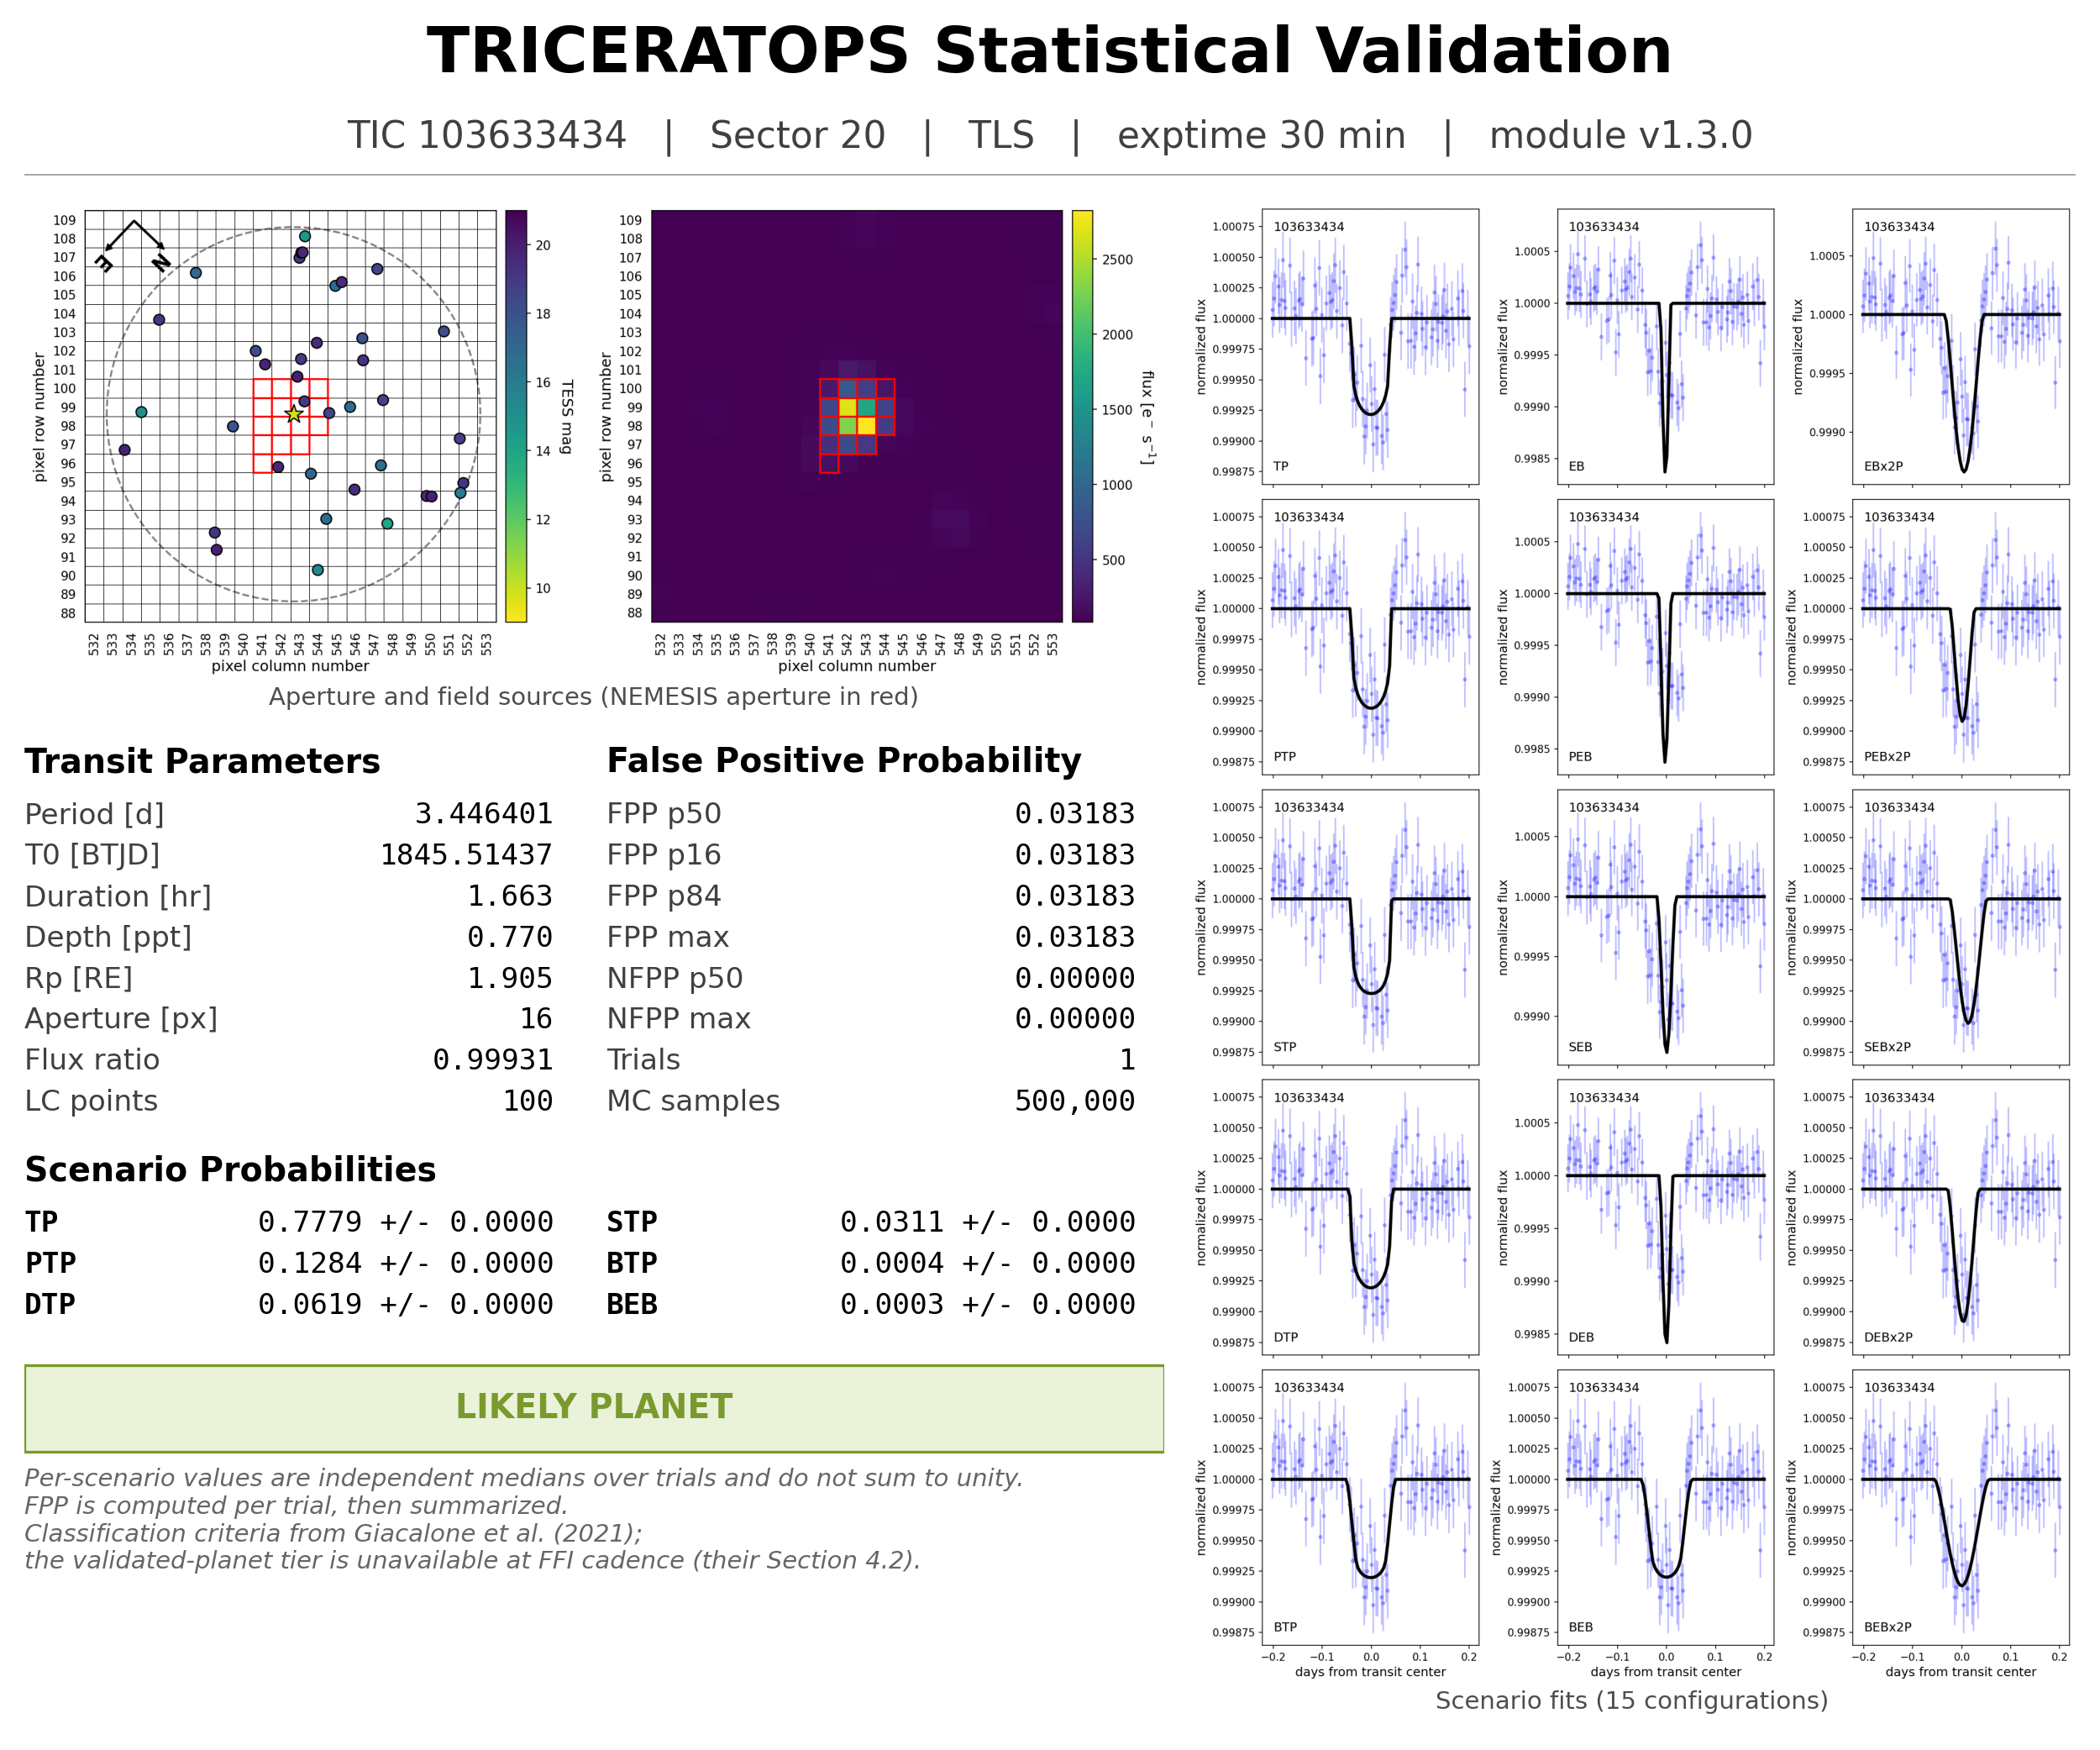

Displayed TRICERATOPS report page.


In [10]:

from pathlib import Path
from IPython.display import Image, display

tic_id = 103633434
sector = 20

page_png = (
    Path.home()
    / "nemesis_tutorials"
    / "toi1235_s20"
    / "triceratops_tutorial"
    / f"TIC_{tic_id}_Sector_{sector:04d}_TRICERATOPS_page.png"
)

if not page_png.is_file():
    raise FileNotFoundError(
        f"TRICERATOPS report panel not found: {page_png}"
    )

display(Image(filename=str(page_png), width=1000))
print("Displayed TRICERATOPS report page.")
